# Ejercicio 9: Reconstrucción tomográfica con regularización cuadrática

Estudiamos cómo cambia la reconstrucción con A7 al variar el nivel de ruido sigma y la intensidad de la regularización lambda. La función a minimizar es J(x) = 1/2 * (||A7 x - b_sigma||^2 + lambda * ||D x||^2), y su gradiente es A7^T (A7 x - b_sigma) + lambda * D^T D x.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})

# la celda de siempre: fantoma y matrices de los ej. anteriores, las redefino pq cada notebook tiene que andar solo
X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)
n = 8
x_fantoma = X_fantoma.reshape(-1)


def mascara_rayo(n, direccion, s):
    """Matriz n x n con 1 donde alpha*i + beta*j == s (centros de pixel)."""
    alpha, beta = direccion
    i, j = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")
    return (alpha * i + beta * j == s).astype(float)


def matriz_proyeccion(n, direcciones):
    """Devuelve (A, rayos): A en R^{m x n^2} y la lista [((alpha, beta), s), ...]."""
    i, j = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")
    filas, rayos = [], []
    for (alpha, beta) in direcciones:
        valores_s = np.unique(alpha * i + beta * j)  # ordenados de menor a mayor
        for s in valores_s:
            filas.append(mascara_rayo(n, (alpha, beta), s).reshape(-1))
            rayos.append(((alpha, beta), int(s)))
    return np.array(filas), rayos


D2 = [(1, 0), (0, 1)]
D4 = D2 + [(1, 1), (1, -1)]
D7 = D4 + [(2, 1), (1, 2), (3, 1)]
A7, rayos7 = matriz_proyeccion(n, D7)

# Mediciones ideales y ruido (misma semilla y mismo z en todos los ejercicios)
b7 = A7 @ x_fantoma
escala = np.sqrt(np.mean(b7 ** 2))
# misma semilla que en el ej. 6, si no los numeros no coinciden con los de alla
rng = np.random.default_rng(912)
z = rng.standard_normal(b7.shape)


def medicion_ruidosa(sigma):
    return b7 + sigma * escala * z

## Inciso a)

Con la imagen vectorizada por filas, el píxel (i, j) ocupa la posición k = i*n + j. Las filas de Dh calculan X[i, j+1] - X[i, j]: un -1 en la columna k y un +1 en la columna k + 1, para j de 0 a n-2. Las filas de Dv calculan X[i+1, j] - X[i, j]: un -1 en la columna k y un +1 en la columna k + n, para i de 0 a n-2. La función matriz_diferencias(n) devuelve D con Dh arriba y Dv abajo.

In [ ]:
def matriz_diferencias(n):
    # D = [Dh; Dv] en R^{2n(n-1) x n^2}. Primero las diferencias horizontales, luego las verticales
    filas = 2 * n * (n - 1)
    D = np.zeros((filas, n * n))
    r = 0
    for i in range(n):                  # horizontales: X[i, j+1] - X[i, j]
        for j in range(n - 1):
            k = i * n + j
            D[r, k], D[r, k + 1] = -1.0, 1.0
            r += 1
    for i in range(n - 1):              # verticales: X[i+1, j] - X[i, j]
        for j in range(n):
            k = i * n + j
            D[r, k], D[r, k + n] = -1.0, 1.0
            r += 1
    assert r == filas
    return D

# chequeos del enunciado: 112x64 y un -1 y un +1 por fila
D = matriz_diferencias(n)
print("D.shape =", D.shape, "(esperado: (112, 64))")
print("cada fila tiene exactamente un -1 :", np.all((D == -1).sum(axis=1) == 1))
print("cada fila tiene exactamente un +1 :", np.all((D == 1).sum(axis=1) == 1))

D.shape = (112, 64) (esperado: (112, 64))
cada fila tiene exactamente un -1 : True
cada fila tiene exactamente un +1 : True


## Inciso b) 

In [3]:
# imagen toda de unos, D tiene que dar cero
x_constante = np.ones(n ** 2)
print("||D x_constante||  =", np.linalg.norm(D @ x_constante))
print("||D x_fantoma||    =", np.linalg.norm(D @ x_fantoma))

||D x_constante||  = 0.0
||D x_fantoma||    = 2.705549851693737


Cada fila de D resta dos píxeles vecinos. Si todos los píxeles valen lo mismo, cada resta da 1 - 1 = 0 y entonces D x_constante es cero: una imagen sin variaciones no tiene falta de suavidad. En cambio el fantoma tiene bordes y regiones con distinta atenuación, y por eso ||D x_fantoma|| es aproximadamente 2,71, mayor que cero.

Además, como la grilla es conexa (cualquier píxel se une con cualquier otro por una cadena de vecinos), D x = 0 obliga a que todos los píxeles sean iguales. La penalización no ve el nivel global de la imagen, solo sus variaciones.

## Inciso c) Interpretación de J

El primer término, ||A7 x - b_sigma||^2, es la fidelidad a los datos: qué tan lejos están las mediciones simuladas con x de las mediciones obtenidas.

El segundo término, ||D x||^2, es la suma de los cuadrados de las diferencias entre píxeles vecinos. Mide la falta de suavidad de la imagen: vale cero para imágenes constantes, es chico para imágenes suaves y grande para imágenes con mucho ruido granular o muchos bordes.

El parámetro lambda (lambda >= 0) balancea ambos términos. Con lambda = 0 se recupera mínimos cuadrados puro, que ajusta los datos incluido el ruido. Al aumentar lambda se prefieren imágenes más suaves a costa de un peor ajuste, y con lambda muy grande la solución tiende a una imagen constante.

La regularización agrega un supuesto a priori: las imágenes tomográficas tienden a variar suavemente entre píxeles vecinos, mientras que el ruido produce diferencias grandes y erráticas. Además J sigue siendo cuadrática, con Hessiana A7^T A7 + lambda D^T D, que es definida positiva porque A7^T A7 lo es, así que sigue teniendo un único mínimo.

## Inciso d) 

In [ ]:
# mismo z para los tres, solo cambia cuanto ruido
sigmas = [0.0, 0.10, 0.20]
lambdas = [0.0, 0.1, 0.3, 1.0]
escala = np.sqrt(np.mean(b7 ** 2))
b_sigma = {sg: b7 + sg * escala * z for sg in sigmas}   # mismo z en los tres casos
for sg in sigmas:
    print(f"sigma={sg:.2f}:  ||ruido|| = {np.linalg.norm(b_sigma[sg]-b7):.4f}")

sigma=0.00:  ||ruido|| = 0.0000
sigma=0.10:  ||ruido|| = 1.3256
sigma=0.20:  ||ruido|| = 2.6512


## Inciso e) y f) 

Para elegir alpha evaluamos el descenso con alpha = kappa / L, donde L es el mayor autovalor de A7^T A7 + lambda D^T D, es decir la constante de Lipschitz del gradiente (la Hessiana de J es constante). Lo probamos en el caso más exigente, lambda = 1, que es el que tiene el mayor L.

El criterio de parada no usa el fantoma. Se detiene cuando la norma del gradiente es <= 1e-8 * ||A7^T b_sigma||, o cuando la variación relativa del costo es <= 1e-14, o al llegar a 20000 iteraciones.

In [5]:
AtA, DtD = A7.T @ A7, D.T @ D

def costo_J(x, b, lam):
    return 0.5 * (np.sum((A7 @ x - b) ** 2) + lam * np.sum((D @ x) ** 2))

def grad_J(x, b, lam):
    return A7.T @ (A7 @ x - b) + lam * (DtD @ x)

def constante_L(lam):
    return np.linalg.eigvalsh(AtA + lam * DtD)[-1]

def gd_regularizado(b, lam, alpha, x_ref=None, max_iter=20000, tol_grad=1e-8, tol_costo=1e-14):
    x = np.zeros(n ** 2)
    ref = tol_grad * np.linalg.norm(A7.T @ b)
    costos, errores = [], []
    motivo = "max_iter"
    for t in range(max_iter + 1):
        g = grad_J(x, b, lam)
        c = costo_J(x, b, lam)
        costos.append(c)
        if x_ref is not None:                       # x_ref SOLO para graficar el error, nunca para cortar
            errores.append(np.linalg.norm(x - x_ref) / np.linalg.norm(x_ref))
        if np.linalg.norm(g) <= ref:
            motivo = "gradiente"; break
        if t > 0 and abs(costos[-2] - c) <= tol_costo * max(1.0, abs(c)):
            motivo = "costo"; break
        if not np.isfinite(c) or c > 1e100:
            motivo = "diverge"; break
        if t < max_iter:
            x = x - alpha * g
    return x, np.array(costos), np.array(errores), t, motivo

# --- Evaluación de tasas de aprendizaje (caso sigma=0.10, lambda=1) ---
lam_test, b_test = 1.0, b_sigma[0.10]
L_test = constante_L(lam_test)
print(f"L(lambda={lam_test}) = {L_test:.3f}")
print(f"{'kappa':>6}{'alpha':>10}{'iter':>7}  motivo")
for kp in [0.25, 1.0, 1.9, 2.1]:
    a = kp / L_test
    xk, ck, _, itk, mot = gd_regularizado(b_test, lam_test, a, max_iter=1500)
    print(f"{kp:>6}{a:>10.5f}{itk:>7d}  {mot}")

L_max = max(constante_L(l) for l in lambdas)
alpha = 1.0 / L_max
print(f"\nSe usa alpha = 1/L_max = {alpha:.5f} para todos los casos")

L(lambda=1.0) = 36.477
 kappa     alpha   iter  motivo
  0.25   0.00685    533  costo
   1.0   0.02741    137  costo
   1.9   0.05209    161  costo
   2.1   0.05757   1187  diverge

Se usa alpha = 1/L_max = 0.02741 para todos los casos


Con alpha = 1/L el descenso del costo es monótono y estable. Con alpha cercana a 2/L el costo sigue bajando pero cada vez más lento, porque el error en la dirección de mayor curvatura cambia de signo en cada paso, y con alpha > 2/L el costo diverge. Como L crece con lambda, usamos alpha = 1/L_max con L_max = L(lambda = 1), que es estable para todos los lambda de la grilla.

In [ ]:
res = {}   # (sigma, lambda) -> dict
print(f"{'sigma':>6}{'lambda':>8}{'iter':>7}  {'motivo':<10}{'||r||':>9}{'||Dx||':>9}{'err_rel':>9}{'min':>8}{'max':>8}") #pedi ayuda a la IA aca para armar la tablita
for sg in sigmas:
    for lam in lambdas:
        x, costos, errores, it, mot = gd_regularizado(b_sigma[sg], lam, alpha, x_ref=x_fantoma)
        res[(sg, lam)] = dict(x=x, costos=costos, err=errores, it=it, motivo=mot,
                              resid=np.linalg.norm(A7 @ x - b_sigma[sg]), var=np.linalg.norm(D @ x),
                              err_final=errores[-1])
        r_ = res[(sg, lam)]
        print(f"{sg:>6.2f}{lam:>8.1f}{it:>7d}  {mot:<10}{r_['resid']:>9.4f}{r_['var']:>9.4f}{r_['err_final']:>9.4f}{x.min():>8.3f}{x.max():>8.3f}") 

 sigma  lambda   iter  motivo        ||r||   ||Dx||  err_rel     min     max
  0.00     0.0    783  gradiente    0.0000   2.7055   0.0000  -0.000   0.800
  0.00     0.1    507  gradiente    0.2008   2.5418   0.0423  -0.017   0.795
  0.00     0.3    305  gradiente    0.5040   2.3122   0.0972  -0.040   0.782
  0.00     1.0    135  costo        1.1594   1.8729   0.2000  -0.069   0.733
  0.10     0.0    868  gradiente    0.8893   2.8947   0.2101  -0.141   0.890
  0.10     0.1    555  gradiente    0.9232   2.6490   0.1705  -0.099   0.841
  0.10     0.3    327  costo        1.0617   2.3585   0.1629  -0.079   0.779
  0.10     1.0    137  costo        1.5268   1.8721   0.2243  -0.076   0.720
  0.20     0.0    898  costo        1.7787   3.4295   0.4203  -0.282   0.980
  0.20     0.1    566  costo        1.8114   3.0104   0.3374  -0.215   0.917
  0.20     0.3    329  costo        1.9311   2.5801   0.2814  -0.147   0.841
  0.20     1.0    138  costo        2.3109   1.9612   0.2775  -0.134   0.709

## Inciso g) 

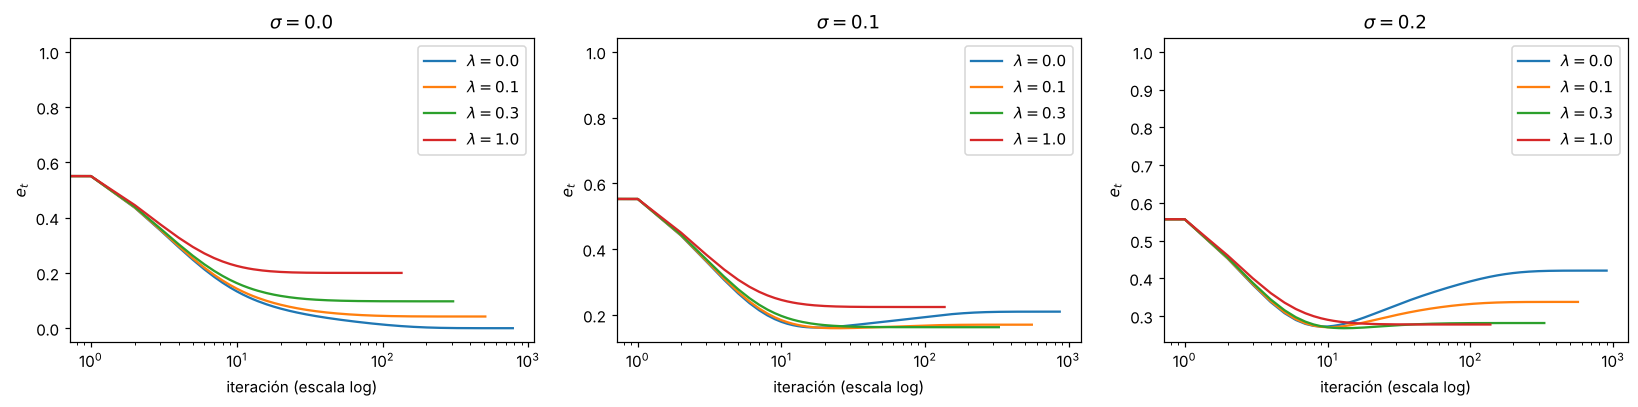

sigma=0.00 lambda=0.0: error final = 0.0000,  mínimo durante el descenso = 0.0000 (it. 783)
sigma=0.10 lambda=0.0: error final = 0.2101,  mínimo durante el descenso = 0.1618 (it. 18)
sigma=0.20 lambda=0.0: error final = 0.4203,  mínimo durante el descenso = 0.2720 (it. 9)


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
for ax, sg in zip(axes, sigmas):
    for lam in lambdas:
        e = res[(sg, lam)]["err"]
        ax.plot(e, label=rf"$\lambda={lam}$")
    ax.set_xscale("log"); ax.set_xlabel("iteración (escala log)"); ax.set_title(rf"$\sigma={sg}$")
    ax.set_ylabel(r"$e_t$"); ax.legend()
plt.tight_layout(); plt.savefig("figuras/ejercicio_9_g.png", dpi=150); plt.show()

# minimo del error a lo largo de las iteraciones, solo con lambda = 0 (no se uso para parar)
for sg in sigmas:
    e = res[(sg, 0.0)]["err"]
    print(f"sigma={sg:.2f} lambda=0.0: error final = {e[-1]:.4f},  mínimo durante el descenso = {e.min():.4f} (it. {int(np.argmin(e))})")

## Inciso h) 

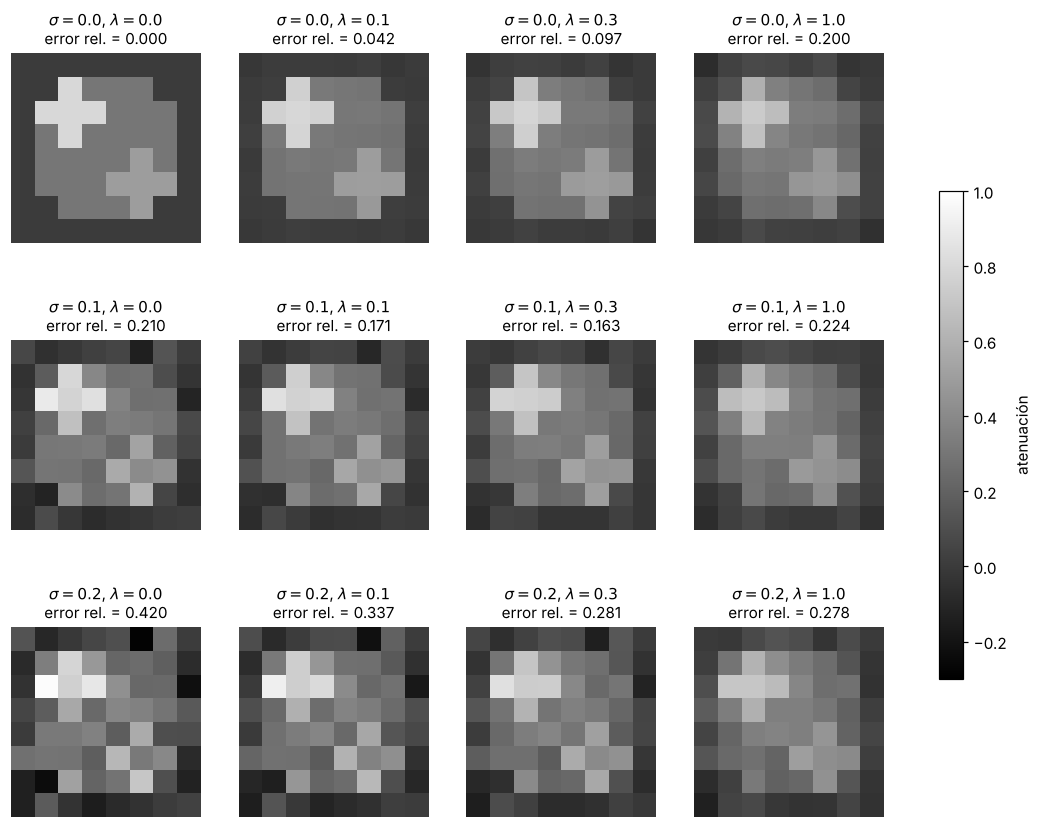

In [ ]:
VMIN, VMAX = -0.3, 1.0     # fijos a mano, nada de autoescala

fig, axes = plt.subplots(len(sigmas), len(lambdas), figsize=(3.2 * len(lambdas), 3.2 * len(sigmas)))
for i, sg in enumerate(sigmas):
    for j, lam in enumerate(lambdas):
        r_ = res[(sg, lam)]
        h = axes[i, j].imshow(r_["x"].reshape(n, n), cmap="gray", vmin=VMIN, vmax=VMAX)
        axes[i, j].set_title(rf"$\sigma={sg}$, $\lambda={lam}$" + f"\nerror rel. = {r_['err_final']:.3f}", fontsize=10)
        axes[i, j].axis("off")
fig.colorbar(h, ax=axes, shrink=0.6, label="atenuación")
plt.savefig("figuras/ejercicio_9_h.png", dpi=150, bbox_inches="tight"); plt.show()

## Inciso i) 

In [9]:
E_rel = np.array([[res[(sg, lam)]["err_final"] for lam in lambdas] for sg in sigmas])
R_nrm = np.array([[res[(sg, lam)]["resid"] for lam in lambdas] for sg in sigmas])

print("Error relativo (filas: sigma, columnas: lambda)")
print(f"{'':>8}" + "".join(f"{l:>9.1f}" for l in lambdas) + f"{'mejor lambda':>15}")
for i, sg in enumerate(sigmas):
    print(f"{sg:>8.2f}" + "".join(f"{v:>9.4f}" for v in E_rel[i]) + f"{lambdas[int(np.argmin(E_rel[i]))]:>15.1f}")
print("\nNorma del residuo ||A7 x - b_sigma||")
print(f"{'':>8}" + "".join(f"{l:>9.1f}" for l in lambdas))
for i, sg in enumerate(sigmas):
    print(f"{sg:>8.2f}" + "".join(f"{v:>9.4f}" for v in R_nrm[i]))

Error relativo (filas: sigma, columnas: lambda)
              0.0      0.1      0.3      1.0   mejor lambda
    0.00   0.0000   0.0423   0.0972   0.2000            0.0
    0.10   0.2101   0.1705   0.1629   0.2243            0.3
    0.20   0.4203   0.3374   0.2814   0.2775            1.0

Norma del residuo ||A7 x - b_sigma||
              0.0      0.1      0.3      1.0
    0.00   0.0000   0.2008   0.5040   1.1594
    0.10   0.8893   0.9232   1.0617   1.5268
    0.20   1.7787   1.8114   1.9311   2.3109


## Inciso j) 

Los números citados corresponden a las tablas de arriba, con la semilla 912.

En qué casos la regularización mejoró la reconstrucción obtenida con lambda = 0? cuando hay ruido (sigma = 0,10 y sigma = 0,20). Sin ruido, la solución de mínimos cuadrados recupera el fantoma de forma exacta (error cercano a cero, porque A7 tiene rango columna completo y los datos son consistentes) y cualquier lambda > 0 solo agrega sesgo: el error crece con lambda (0,042 para lambda = 0,1; 0,097 para 0,3; 0,200 para 1), porque el fantoma no es perfectamente suave y la penalización lo suaviza. Con ruido, en cambio, la regularización reduce el error: para sigma = 0,10 pasa de 0,210 (lambda = 0) a 0,163 (lambda = 0,3), una reducción de cerca del 22 %, y para sigma = 0,20 pasa de 0,420 a 0,278 (lambda = 1), cerca de un 34 %.

Cómo cambió el valor más conveniente de lambda al aumentar el ruido? aumentó. Dentro de la grilla, el mejor lambda es 0 para sigma = 0, 0,3 para sigma = 0,10 y 1 para sigma = 0,20. Con más ruido los datos son menos confiables y conviene darle más peso al supuesto de suavidad, es el compromiso entre sesgo y varianza, porque la regularización agrega sesgo pero reduce la varianza que el ruido induce en la solución. Para sigma = 0,20 los errores con lambda = 0,3 (0,281) y lambda = 1 (0,278) son casi iguales, así que el óptimo está en una zona bastante plana. Además, este mejor lambda se identifica acá porque conocemos el fantoma, mientras que en un caso real (Ejercicio 10) hay que elegirlo sin.

Qué efecto produjo una regularización excesiva? las reconstrucciones se ven borrosas, los bordes se difuminan, los picos de atenuación (0,8) se aplanan (con lambda = 1 el máximo baja a 0,71 o 0,73 y los mínimos negativos se acercan a cero) y las regiones se mezclan con las vecinas. Para sigma = 0 y sigma = 0,10 el error con lambda = 1 (0,200 y 0,224) es peor que el óptimo, y para sigma = 0,10 incluso peor que sin regularizar (0,210). Además el residuo crece con lambda, porque la imagen deja de explicar las mediciones. Un lambda demasiado chico deja pasar el ruido y uno demasiado grande elimina detalle. Con sigma = 0,20, lambda = 1 todavía no es excesivo porque el ruido es lo bastante grande como para justificarlo.

Sobre el criterio de parada, en las curvas de error con ruido se ve que el error del gradiente descendiente sin regularizar (lambda = 0) primero baja y después sube hacia el error de mínimos cuadrados. El mínimo ocurre en pocas iteraciones, mucho antes de converger: 18 iteraciones con sigma = 0,10 y 9 con sigma = 0,20, con errores de 0,162 y 0,272. Es decir, detener antes el algoritmo (early stopping) actúa también como una regularización implícita: las direcciones de mayor curvatura, bien determinadas por los datos, se ajustan primero, y las de menor curvatura, donde vive buena parte del ruido amplificado, se ajustan al final. Nuestro criterio de parada no usa el error, que en la práctica no se conoce, así que las curvas finales corresponden al mínimo del funcional y no al mejor punto intermedio.